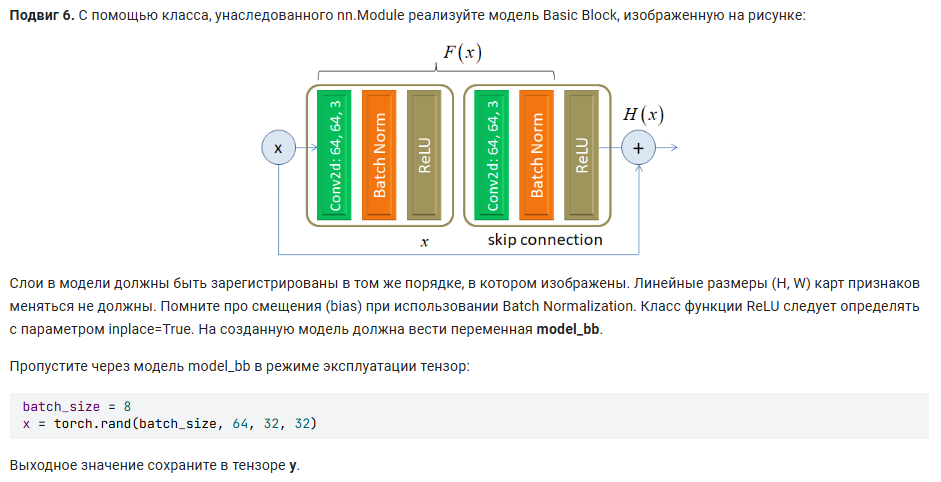

In [80]:
import torch
import torch.nn as nn

# здесь объявляйте класс модели
class BasicBlock(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.layers = nn.ModuleList([nn.Sequential(
            nn.Conv2d(64, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        ) for _ in range(2)])

    def forward(self, x):
        f = x
        for layer in self.layers:
            f = layer(x)
        return f + x


batch_size = 8
x = torch.rand(batch_size, 64, 32, 32) # тензор x в программе не менять

# здесь продолжайте программу
model_bb = BasicBlock()
model_bb.eval()

y = model_bb(x)

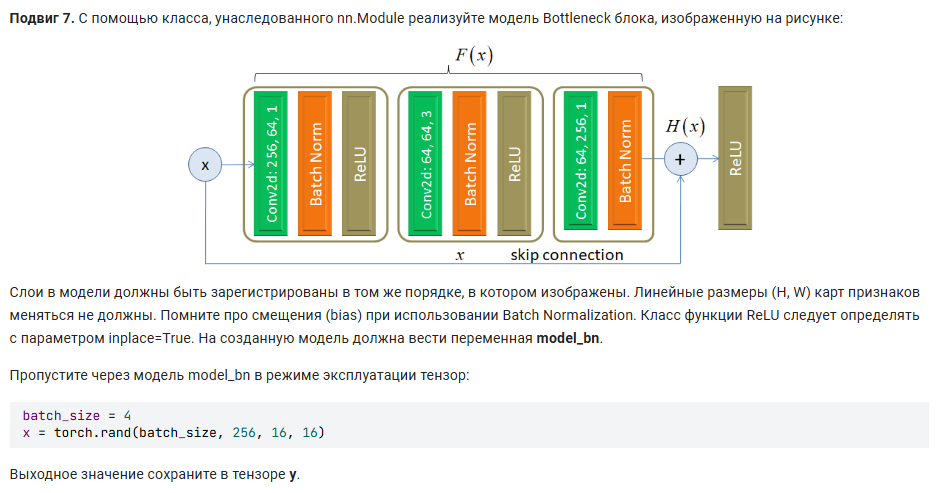

In [104]:
import torch
import torch.nn as nn

# здесь объявляйте класс модели
class Bottleneck (nn.Module):
    def __init__(self):
        super().__init__()
        
        self.net = nn.Sequential(
            nn.Conv2d(256, 64, 1, padding=0, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 256, 1, padding=0, bias=False),
            nn.BatchNorm2d(256),
        )

    def forward(self, x):
        # print(x.shape, self.net(x).shape)
        return torch.relu(self.net(x) + x)


batch_size = 4
x = torch.rand(batch_size, 256, 16, 16) # тензор x в программе не менять

# здесь продолжайте программу
model_bn = Bottleneck ()
model_bn.eval()

y = model_bn(x)

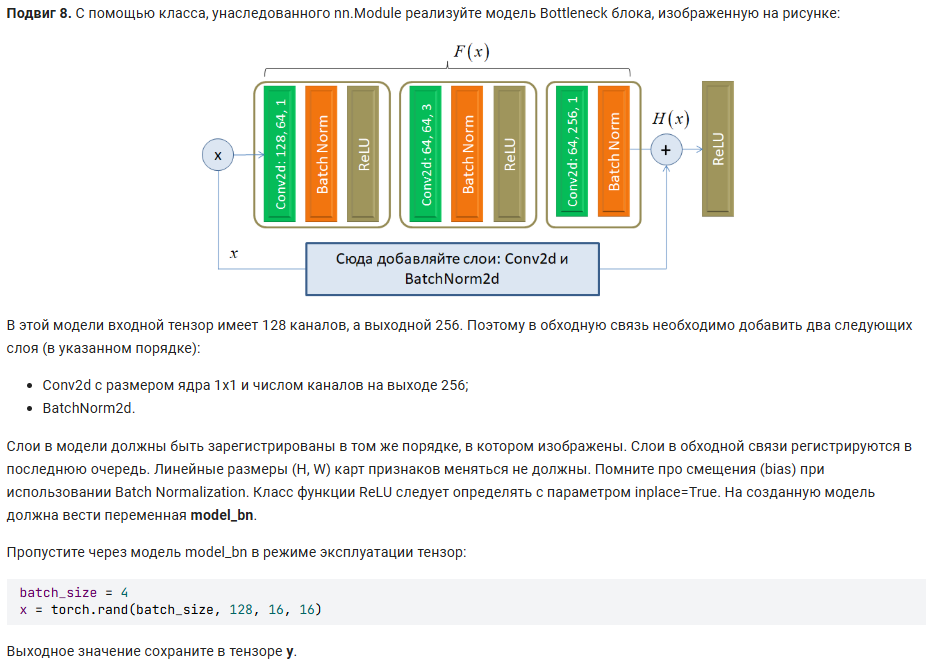

In [106]:
import torch
import torch.nn as nn

# здесь объявляйте класс модели
class Bottleneck (nn.Module):
    def __init__(self):
        super().__init__()
        
        self.net = nn.Sequential(
            nn.Conv2d(128, 64, 1, padding=0, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            
            nn.Conv2d(64, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            
            nn.Conv2d(64, 256, 1, padding=0, bias=False),
            nn.BatchNorm2d(256),
        )
        self.skip = nn.Sequential(
            nn.Conv2d(128, 256, 1, padding=0, bias=False),
            nn.BatchNorm2d(256))

    def forward(self, x):
        # print(x.shape, self.net(x).shape)
        return torch.relu(self.net(x) + self.skip(x))


batch_size = 4
x = torch.rand(batch_size, 128, 16, 16)

# здесь продолжайте программу
model_bn = Bottleneck ()
model_bn.eval()

y = model_bn(x)